# Notebook 04: Feature Engineering for One Daily Next-Day Forecast
**Project F1: Electricity Consumption Analysis and Forecasting in Morocco**

## Objective and user-selected forecast design
Issue **one forecast batch per day**, predicting all 144 ten-minute demand readings of the next calendar day.

Our issue time is **23:50 on the preceding day**, immediately after that timestamp's reading becomes available. Every target from next-day 00:00 through 23:50 shares this one origin. The leads therefore vary from **10 minutes to 24 hours**. We assume no material reporting or computation delay; practical deployment would need an explicit latency allowance.

This implements the user's choice of whole-next-day forecasting. The 23:50 issue convention is an implementation choice that makes the available readings explicit. It replaces the earlier rolling fixed-lead version, which has been archived as superseded.

## What changes
- Origin-relative history and weather features are frozen across all 144 targets in a batch.
- Known target calendar fields can vary across the next day.
- Previous-day and previous-week same-clock readings also vary across the target day, but are already known at the issue time.
- **Origin persistence and previous-day demand are now different baselines.** Persistence repeats the final reading across the next day; previous day repeats yesterday's entire daily shape.

We produce candidate predictors, a source-time dictionary, availability checks, chronological splits, and a separate feature table/manifest. No prediction model is fitted here. Demand and weather retain source units. Earlier descriptive exposure of the whole file must still be disclosed.

## 1. Setup and Shared Paths
Use the project's `.venv` kernel and run cells in order. Figures are saved as PNG and SVG and summaries as CSV.

The checked Parquet dataset remains unchanged. New artifacts explicitly use `daily_batch` names so they cannot be confused with the archived rolling design.

In [1]:
import sys
import importlib
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display

current_dir=Path.cwd().resolve()
PROJECT_ROOT=next((p for p in [current_dir,*current_dir.parents]
                   if (p/"src/config.py").is_file()),None)
if PROJECT_ROOT is None:raise FileNotFoundError("Open the Project folder containing src/config.py.")
if str(PROJECT_ROOT) not in sys.path:sys.path.insert(0,str(PROJECT_ROOT))
import src.config as cfg
importlib.reload(cfg)
from src.config import PROCESSED_DIR,FIGURES_DIR,TABLES_DIR,ZONES,TRAIN_END,VAL_END

FEATURE_FIGURES=FIGURES_DIR/"04_feature_engineering"
FEATURE_TABLES=TABLES_DIR/"04_feature_engineering"
for folder in [FEATURE_FIGURES,FEATURE_TABLES]:folder.mkdir(parents=True,exist_ok=True)
WEATHER=["temperature","humidity","wind_speed","general_diffuse_flows","diffuse_flows"]
SERIES=[*ZONES,"total"]
COLORS={"zone1":"#0072B2","zone2":"#D55E00","zone3":"#009E73","total":"#5B3C88"}
LABELS={"zone1":"Zone 1","zone2":"Zone 2","zone3":"Zone 3","total":"Combined"}
STEP_MINUTES=10
STEPS_PER_DAY=144
assert STEP_MINUTES==10 and STEPS_PER_DAY==144,"This contract is for ten-minute daily batches."
ISSUE_OFFSET=pd.Timedelta(minutes=10)
TRAIN_CUTOFF=pd.Timestamp(TRAIN_END).normalize()+pd.Timedelta(days=1)
VAL_CUTOFF=pd.Timestamp(VAL_END).normalize()+pd.Timedelta(days=1)
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":110,"font.size":11,"axes.spines.top":False,
                     "axes.spines.right":False,"svg.fonttype":"none"})

def save_table(table,name,index=True):
    table.to_csv(FEATURE_TABLES/f"{name}.csv",index=index,encoding="utf-8")

def show_figure(fig,name):
    fig.tight_layout()
    fig.savefig(FEATURE_FIGURES/f"{name}.png",dpi=200,bbox_inches="tight")
    fig.savefig(FEATURE_FIGURES/f"{name}.svg",bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Python:",sys.executable)
print("One issue at previous-day 23:50; 144 next-day targets; leads 10 minutes–24 hours.")
print("Target-date cutoffs:",TRAIN_CUTOFF,"and",VAL_CUTOFF)

Python: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\.venv\Scripts\python.exe
One issue at previous-day 23:50; 144 next-day targets; leads 10 minutes–24 hours.
Target-date cutoffs: 2017-09-01 00:00:00 and 2017-11-01 00:00:00


## 2. Load Data and Define a Shared Daily Origin
All forecasts for January 10, for example, are issued after the January 9 **23:50** reading. Targets at 00:00, 12:00, and 23:50 have different lead times, but the same information cutoff.

We do not update any forecast in that batch using observations arriving during January 10.

In [2]:
clean_path=PROCESSED_DIR/"tetuan_clean.parquet"
raw=pd.read_parquet(clean_path)
assert raw.shape==(52_416,9)
assert set(raw.columns)=={"datetime",*WEATHER,*ZONES}
assert raw["datetime"].is_unique and raw["datetime"].is_monotonic_increasing
assert raw["datetime"].diff().dropna().eq(pd.Timedelta(minutes=10)).all()
assert raw["datetime"].min()==pd.Timestamp("2017-01-01")
assert raw["datetime"].max()==pd.Timestamp("2017-12-30 23:50")
assert not raw.isna().any().any()
assert np.isfinite(raw[WEATHER+ZONES].to_numpy()).all()
assert raw[ZONES].gt(0).all().all()
example_target=pd.Timestamp("2017-01-10 20:00")
example_origin=example_target.normalize()-ISSUE_OFFSET
example_targets=pd.DatetimeIndex(["2017-01-10 00:00","2017-01-10 12:00","2017-01-10 23:50"])
example_sources=pd.DataFrame({"target_time":example_targets,"origin_time":example_origin,
    "lead_minutes":(example_targets-example_origin)/pd.Timedelta(minutes=1),
    "previous_day_source":example_targets-pd.Timedelta(days=1),
    "previous_week_source":example_targets-pd.Timedelta(days=7)})
assert example_sources["previous_day_source"].le(example_origin).all()
display(example_sources)
save_table(example_sources,"01_example_source_times",index=False)

,target_time,origin_time,lead_minutes,previous_day_source,previous_week_source
0,2017-01-10 00:00:00,2017-01-09 23:50:00,10.0,2017-01-09 00:00:00,2017-01-03 00:00:00
1,2017-01-10 12:00:00,2017-01-09 23:50:00,730.0,2017-01-09 12:00:00,2017-01-03 12:00:00
2,2017-01-10 23:50:00,2017-01-09 23:50:00,1440.0,2017-01-09 23:50:00,2017-01-03 23:50:00


### Interpretation: One Issue, Different Targets
The January 10 batch shares an origin of **January 9 at 23:50**. The first target is ten minutes later; the last is 24 hours later.

The previous-day source for the first target is January 9 at 00:00, while the previous-day source for the last target is January 9 at 23:50. Both are known at the daily issue. Origin persistence instead uses January 9 at 23:50 for every target.

An origin-minus-seven-days lag and a target-minus-seven-days lag remain different quantities. Target-relative lags have different offsets from the shared origin depending on the target's lead.

## 3. Visualise the Daily Information Boundary
The origin is zero on the axis. Blue items use observations already available at issue time. Orange items are the 144 next-day outcomes being forecast. Their realised measurements are unavailable to this batch.

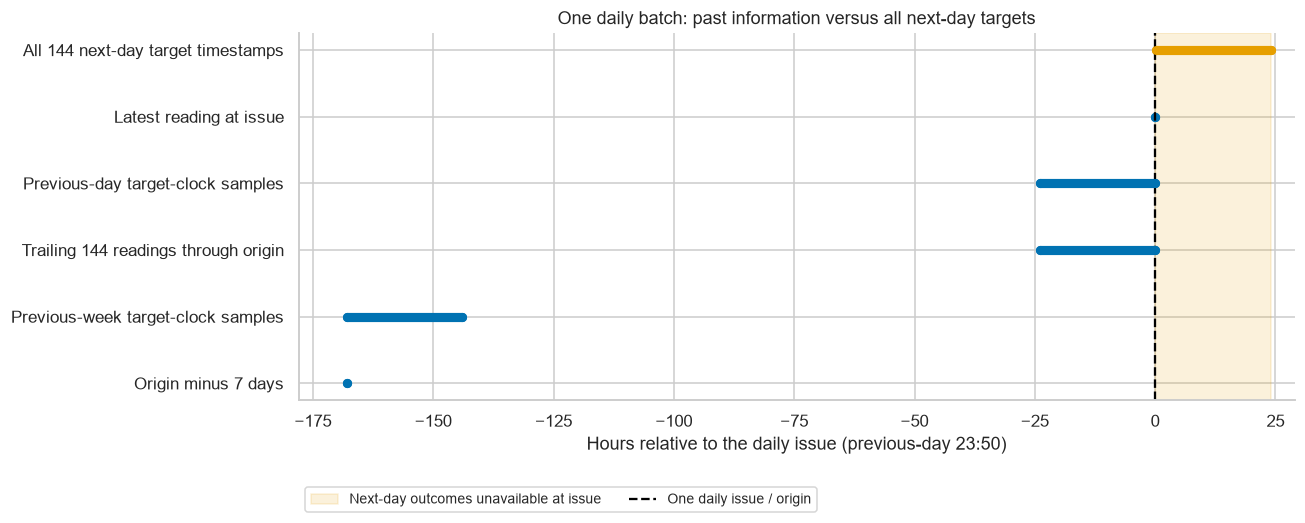

In [3]:
fig,ax=plt.subplots(figsize=(12,5))
ax.axvspan(0,24,color="#E69F00",alpha=.14,label="Next-day outcomes unavailable at issue")
ax.axvline(0,color="black",linestyle="--",linewidth=1.5,label="One daily issue / origin")
items=[("Origin minus 7 days",-168,-168,"#0072B2"),
       ("Previous-week target-clock samples",-167-5/6,-144,"#0072B2"),
       ("Trailing 144 readings through origin",-23-5/6,0,"#0072B2"),
       ("Previous-day target-clock samples",-23-5/6,0,"#0072B2"),
       ("Latest reading at issue",0,0,"#0072B2"),
       ("All 144 next-day target timestamps",1/6,24,"#E69F00")]
for y,(label,first,last,color) in enumerate(items):
    ax.plot([first,last],[y,y],linewidth=6,solid_capstyle="round",color=color)
    ax.scatter([first,last],[y,y],s=25,color=color)
ax.set(yticks=range(len(items)),yticklabels=[x[0] for x in items],xlim=(-178,29),
       xlabel="Hours relative to the daily issue (previous-day 23:50)",
       title="One daily batch: past information versus all next-day targets")
ax.legend(loc="upper left",bbox_to_anchor=(0,-.22),ncol=2,fontsize=9)
show_figure(fig,"01_source_origin_target_timeline")

## 4. Build Features at the Daily Issue, Not at Later Target Times
For each source series, calculate origin-relative lags and rolling summaries on the original time index, then look them up at the repeated daily origin. Assign those values to target rows without aligning them on the duplicated origin index.

**Calendar:** target hour, minute, weekday, month, weekend, slot, and cyclic day/week/year encodings are known ahead. Annual encodings are candidates, not proof of repeating annual behaviour. No unverified holiday flags are invented.

**Demand history:** origin readings/lags and trailing summaries are frozen across a daily batch. Previous-day/previous-week target-clock readings and seven-day same-clock means can vary by target slot because the entire previous day is already known.

**Weather history:** origin readings, trailing 144-reading means, and earlier changes are also frozen within each batch. No target-day observed weather is used.

Window definitions remain inclusive: six readings span origin minus 50 minutes through origin; 144 span origin minus 23 hours 50 minutes through origin; 1,008 span origin minus 6 days 23 hours 50 minutes through origin.

The dictionary records whether a source rule is relative to the origin or target, its earliest/latest lag, and its possible origin-relative offsets. Target-relative source offsets vary with lead. We do not fit scalers, imputers, feature selection, or thresholds here.

In [4]:
def build_features(data):
    """One issue at previous-day23:50; predictors for all144 next-day targets."""
    source=data.set_index("datetime")
    target_time=pd.DatetimeIndex(source.index)
    origin_time=target_time.normalize()-ISSUE_OFFSET
    lead_steps=((target_time-origin_time)/pd.Timedelta(minutes=10)).astype(int)
    assert set(lead_steps)==set(range(1,145))
    values={}
    records=[]

    def at_issue(series):
        return pd.Series(series.reindex(origin_time).to_numpy(),index=target_time)

    def add(name,value,group,definition,reference="calendar",earliest=None,latest=None):
        values[name]=value
        record={"feature":name,"group":group,"definition":definition,"source_reference":reference,
                "earliest_source_lag_steps":earliest,"latest_source_lag_steps":latest}
        for label,lag in [("earliest",earliest),("latest",latest)]:
            if reference=="calendar":minimum=maximum=None
            elif reference=="origin":minimum=maximum=-lag*10
            else:minimum=10-lag*10;maximum=1440-lag*10
            record[f"{label}_origin_offset_min_minutes"]=minimum
            record[f"{label}_origin_offset_max_minutes"]=maximum
        records.append(record)

    slot=target_time.hour*6+target_time.minute//10
    fraction_of_day=slot/144
    week_position=target_time.day_of_week+fraction_of_day
    year_length=np.where(target_time.is_leap_year,366,365)
    year_position=(target_time.day_of_year-1+fraction_of_day)/year_length
    calendar={"target_hour":target_time.hour,"target_minute":target_time.minute,
        "target_weekday":target_time.day_of_week,"target_month":target_time.month,
        "target_is_weekend":(target_time.day_of_week>=5).astype(int),"target_slot":slot,
        "target_day_sin":np.sin(2*np.pi*fraction_of_day),"target_day_cos":np.cos(2*np.pi*fraction_of_day),
        "target_week_sin":np.sin(2*np.pi*week_position/7),"target_week_cos":np.cos(2*np.pi*week_position/7),
        "target_year_sin":np.sin(2*np.pi*year_position),"target_year_cos":np.cos(2*np.pi*year_position)}
    for name,value in calendar.items():add(name,value,"calendar","Known target-time calendar field")

    for zone in ZONES:
        series=source[zone]
        add(f"{zone}_at_origin",at_issue(series),"load_history","Reading at daily issue","origin",0,0)
        for steps,label in [(1,"10min"),(6,"1h"),(144,"1d"),(1008,"7d")]:
            add(f"{zone}_origin_lag_{label}",at_issue(series.shift(steps)),"load_history",
                f"Reading {steps} ten-minute steps before issue","origin",steps,steps)
        for days in [1,7]:
            steps=days*144
            add(f"{zone}_target_lag_{days}d",series.shift(steps),"load_history",
                f"Same target clock time {days} day(s) earlier","target",steps,steps)
        for window,operations in [(6,["mean"]),(144,["mean","std","min","max"]),(1008,["mean","std"])]:
            rolling=series.rolling(window,min_periods=window)
            for operation in operations:
                calculated=rolling.std(ddof=0) if operation=="std" else getattr(rolling,operation)()
                add(f"{zone}_origin_roll{window}_{operation}",at_issue(calculated),"load_history",
                    f"{operation} of last {window} readings through issue; std ddof=0","origin",window-1,0)
        previous=pd.concat([series.shift(144*k) for k in range(1,8)],axis=1)
        same_clock=previous.mean(axis=1).where(previous.notna().all(axis=1))
        add(f"{zone}_previous7_same_clock_mean",same_clock,"load_history",
            "Mean previous seven daily readings at target clock time","target",1008,144)

    for weather in WEATHER:
        series=source[weather]
        add(f"{weather}_at_origin",at_issue(series),"weather_history","Weather at daily issue","origin",0,0)
        add(f"{weather}_origin_roll144_mean",at_issue(series.rolling(144,min_periods=144).mean()),
            "weather_history","Mean last144 weather readings through issue","origin",143,0)
        add(f"{weather}_origin_change6",at_issue(series-series.shift(6)),"weather_history",
            "Issue reading minus reading six steps earlier","origin",6,0)

    feature_frame=pd.DataFrame(values,index=target_time)
    labels=source[ZONES].rename(columns={z:f"y_{z}" for z in ZONES}).copy()
    labels["y_total"]=labels.sum(axis=1)
    result=pd.concat([feature_frame,labels],axis=1)
    result.insert(0,"lead_steps",lead_steps)
    result.insert(0,"origin_time",origin_time)
    result.insert(0,"target_time",target_time)
    return result.reset_index(drop=True),pd.DataFrame(records)

full_panel,feature_dictionary=build_features(raw)
feature_columns=feature_dictionary["feature"].tolist()
target_columns=[f"y_{s}" for s in SERIES]
assert len(feature_columns)==len(set(feature_columns))==72
assert not set(feature_columns).intersection(target_columns+["target_time","origin_time","lead_steps","split"])
feature_groups=feature_dictionary.groupby("group").size().rename("features").to_frame()
display(feature_groups)
display(feature_dictionary.head(15))
save_table(feature_dictionary,"02_feature_dictionary",index=False)
save_table(feature_groups,"03_feature_group_counts")

,features
group,
calendar,12
load_history,45
weather_history,15


,feature,group,definition,source_reference,earliest_source_lag_steps,latest_source_lag_steps,earliest_origin_offset_min_minutes,earliest_origin_offset_max_minutes,latest_origin_offset_min_minutes,latest_origin_offset_max_minutes
0,target_hour,calendar,Known target-time calendar field,calendar,NaN,NaN,NaN,NaN,NaN,NaN
1,target_minute,calendar,Known target-time calendar field,calendar,NaN,NaN,NaN,NaN,NaN,NaN
2,target_weekday,calendar,Known target-time calendar field,calendar,NaN,NaN,NaN,NaN,NaN,NaN
3,target_month,calendar,Known target-time calendar field,calendar,NaN,NaN,NaN,NaN,NaN,NaN
4,target_is_weekend,calendar,Known target-time calendar field,calendar,NaN,NaN,NaN,NaN,NaN,NaN
5,target_slot,calendar,Known target-time calendar field,calendar,NaN,NaN,NaN,NaN,NaN,NaN
6,target_day_sin,calendar,Known target-time calendar field,calendar,NaN,NaN,NaN,NaN,NaN,NaN
7,target_day_cos,calendar,Known target-time calendar field,calendar,NaN,NaN,NaN,NaN,NaN,NaN
8,target_week_sin,calendar,Known target-time calendar field,calendar,NaN,NaN,NaN,NaN,NaN,NaN
9,target_week_cos,calendar,Known target-time calendar field,calendar,NaN,NaN,NaN,NaN,NaN,NaN


### Interpretation: 72 Candidate Predictors
There are **12 calendar**, **45 demand-history**, and **15 historical-weather** predictors. Three explicit previous-day target lags were added because they are no longer the same as origin persistence.

This is a candidate set, not automatic feature selection. Origin history is frozen within a batch, while known target calendar and past-day target-clock features can vary across its 144 rows.

`lead_steps` is explicit metadata, outside the predictor list; the known target slot already encodes the same position within this daily forecast.

## 5. Remove Only Initial Days Without Enough History
The origin-minus-seven-days lag requires an entire eight-day initial warm-up under this daily issue schedule. We remove incomplete leading days rather than filling missing lag values with future observations or zeros.

Initial warm-up: 1,152 rows; retained: 51,264 rows across 356 whole-day batches.
Every day: one issue,144 targets,lead steps1–144; origin features frozen.


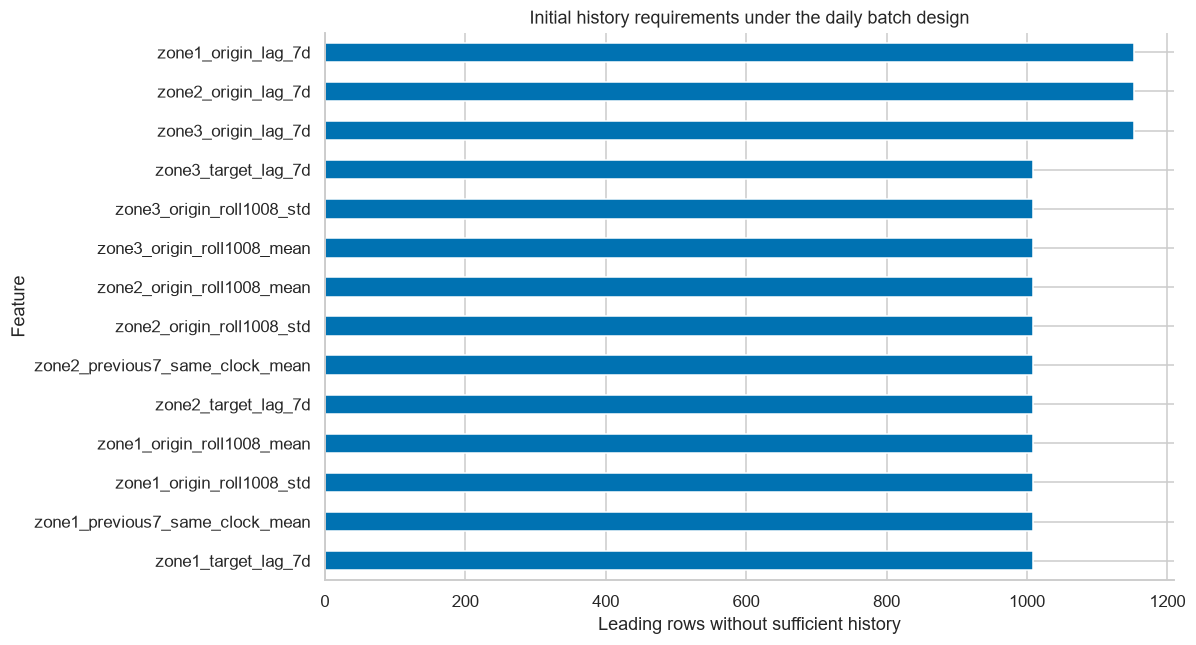

In [5]:
missing_counts=full_panel[feature_columns].isna().sum().rename("initial_missing_rows")
save_table(missing_counts,"04_missing_history_by_feature")
ready=full_panel[feature_columns].notna().all(axis=1)
assert (~ready).sum()==1152
assert not ready.iloc[:1152].any() and ready.iloc[1152:].all()
panel=full_panel.loc[ready].copy().reset_index(drop=True)
assert len(panel)==51264
assert panel["target_time"].iloc[0]==pd.Timestamp("2017-01-09")
assert panel[feature_columns+target_columns].notna().all().all()
assert np.isfinite(panel[feature_columns+target_columns].to_numpy()).all()
target_days=panel["target_time"].dt.normalize()
batch_check=panel.groupby(target_days).agg(targets=("target_time","size"),issues=("origin_time","nunique"),
    minimum_lead=("lead_steps","min"),maximum_lead=("lead_steps","max"))
assert batch_check["targets"].eq(144).all() and batch_check["issues"].eq(1).all()
assert batch_check["minimum_lead"].eq(1).all() and batch_check["maximum_lead"].eq(144).all()
assert panel["origin_time"].eq(target_days-ISSUE_OFFSET).all()
origin_features=feature_dictionary.loc[feature_dictionary["source_reference"].eq("origin"),"feature"].tolist()
assert panel.groupby(target_days)[origin_features].nunique().eq(1).all().all()
save_table(batch_check,"05_daily_batch_structure")
print(f"Initial warm-up: {(~ready).sum():,} rows; retained: {len(panel):,} rows across {len(batch_check)} whole-day batches.")
print("Every day: one issue,144 targets,lead steps1–144; origin features frozen.")
top_missing=missing_counts.nlargest(14).sort_values()
fig,ax=plt.subplots(figsize=(11,6))
top_missing.plot.barh(ax=ax,color="#0072B2")
ax.set(title="Initial history requirements under the daily batch design",
       xlabel="Leading rows without sufficient history",ylabel="Feature")
show_figure(fig,"02_initial_history_requirements")

### Interpretation: Complete Daily Forecast Batches
The first **1,152 rows (eight days)** lack sufficient history. Removing them leaves **51,264 target rows**, or **356 complete daily batches**, beginning on January 9.

Every retained day has exactly one issue, all 144 targets, and leads from one to 144 ten-minute steps. All origin-relative demand and weather features are identical across that day's targets.

This is missing historical context at the start, not missing raw measurements. Window warm-up now follows the daily issue schedule; it should not be confused with the archived rolling design's row-by-row availability.

## 6. Chronological Splits for Daily Batches
Training targets remain January 9–August 31. Validation now includes **September 1–October 31**, and later testing includes **November 1–December 30**.

The first validation batch is issued at August 31,23:50, when the final training reading is assumed available. Thus the last fitted label may equal the issue timestamp; it must never be later. The same principle applies if a final model is refitted using validation outcomes before the first test batch.

There is no intrinsic full-day boundary gap in this design. We assume no material reporting or fitting delay. If a real deployment needs latency, its fitting cutoff must be moved earlier rather than silently using unavailable observations.

Forecasts are frozen during each target day. The following day's batch may use observations from the completed day, because those are then in the past.

,rows,first_target,last_target,first_origin,last_origin
split,,,,,
train,33840,2017-01-09,2017-08-31 23:50:00,2017-01-08 23:50:00,2017-08-30 23:50:00
validation,8784,2017-09-01,2017-10-31 23:50:00,2017-08-31 23:50:00,2017-10-30 23:50:00
test,8640,2017-11-01,2017-12-30 23:50:00,2017-10-31 23:50:00,2017-12-29 23:50:00


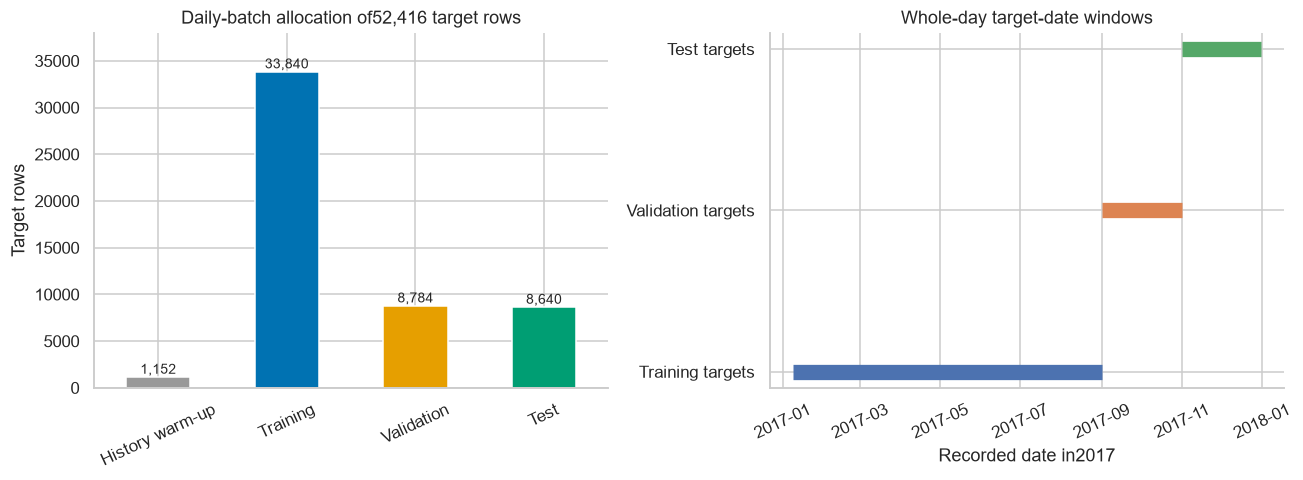

In [6]:
panel["split"]=np.select([panel["target_time"].lt(TRAIN_CUTOFF),panel["target_time"].lt(VAL_CUTOFF)],
                         ["train","validation"],default="test")
train_mask=panel["split"].eq("train")
val_mask=panel["split"].eq("validation")
test_mask=panel["split"].eq("test")
assert panel["split"].value_counts().to_dict()=={"train":33840,"validation":8784,"test":8640}
split_summary=panel.groupby("split").agg(rows=("target_time","size"),
    first_target=("target_time","min"),last_target=("target_time","max"),
    first_origin=("origin_time","min"),last_origin=("origin_time","max"))
split_summary=split_summary.reindex(["train","validation","test"])
save_table(split_summary,"06_chronological_split_summary")
display(split_summary)
latest_training_label=panel.loc[train_mask,"target_time"].max()
assert latest_training_label<=panel.loc[val_mask,"origin_time"].min()
assert panel.loc[val_mask,"target_time"].max()<=panel.loc[test_mask,"origin_time"].min()
assert panel.groupby(panel["target_time"].dt.normalize())["split"].nunique().eq(1).all()

fig,axes=plt.subplots(1,2,figsize=(12,4.5))
counts=pd.Series({"History warm-up":1152,"Training":33840,"Validation":8784,"Test":8640})
counts.plot.bar(ax=axes[0],color=["#999999","#0072B2","#E69F00","#009E73"],rot=25)
axes[0].set(title="Daily-batch allocation of52,416 target rows",ylabel="Target rows",xlabel="",ylim=(0,38000))
for i,value in enumerate(counts):axes[0].text(i,value+350,f"{value:,}",ha="center",fontsize=9)
for y,name in enumerate(["train","validation","test"]):
    block=panel.loc[panel["split"].eq(name),"target_time"]
    axes[1].plot([block.min(),block.max()],[y,y],linewidth=10,solid_capstyle="butt")
axes[1].set(yticks=range(3),yticklabels=["Training targets","Validation targets","Test targets"],
            title="Whole-day target-date windows",xlabel="Recorded date in2017")
axes[1].tick_params(axis="x",rotation=25)
show_figure(fig,"03_split_coverage")

### Interpretation: Updated Windows
- Training: January 9–August 31, **235 batches /33,840 rows**.
- Validation: September 1–October 31, **61 batches /8,784 rows**.
- Test: November 1–December 30, **60 batches /8,640 rows**.

The former September 1/November 1 boundary gaps have been removed because they arose from the previous rolling-origin design. We must use the revised scoring windows consistently and not compare old and new metrics as if they used identical target rows.

Notebook 05 scores validation only. The later test window remains unscored here, although it was explored descriptively earlier.

## 7. Audit Every Source Rule and Recalculate Early/Late Targets
For origin-relative rules, calculate source timestamps from the shared issue. For target-relative rules, calculate them from each target timestamp. Verify all latest source timestamps are at or before the shared issue.

Independently recalculate example lags and rolling means at early, middle, and late target slots. This catches accidental reuse of the old fixed-lead timing.

Every observed feature is available at its daily issue; independent early/middle/late checks passed.


,target_time,feature,engineered,independently_calculated
0,2017-01-10 00:00:00,zone1_at_origin,29115.9494,29115.9494
1,2017-01-10 00:00:00,zone1_target_lag_1d,27268.8608,27268.8608
2,2017-01-10 00:00:00,zone1_target_lag_7d,26661.2658,26661.2658
3,2017-01-10 00:00:00,zone1_origin_roll6_mean,31072.4051,31072.4051
4,2017-01-10 00:00:00,zone1_previous7_same_clock_mean,27876.4557,27876.4557
5,2017-01-10 12:00:00,zone1_at_origin,29115.9494,29115.9494
6,2017-01-10 12:00:00,zone1_target_lag_1d,33770.1266,33770.1266
7,2017-01-10 12:00:00,zone1_target_lag_7d,33168.6076,33168.6076
8,2017-01-10 12:00:00,zone1_origin_roll6_mean,31072.4051,31072.4051
9,2017-01-10 12:00:00,zone1_previous7_same_clock_mean,33295.3345,33295.3345


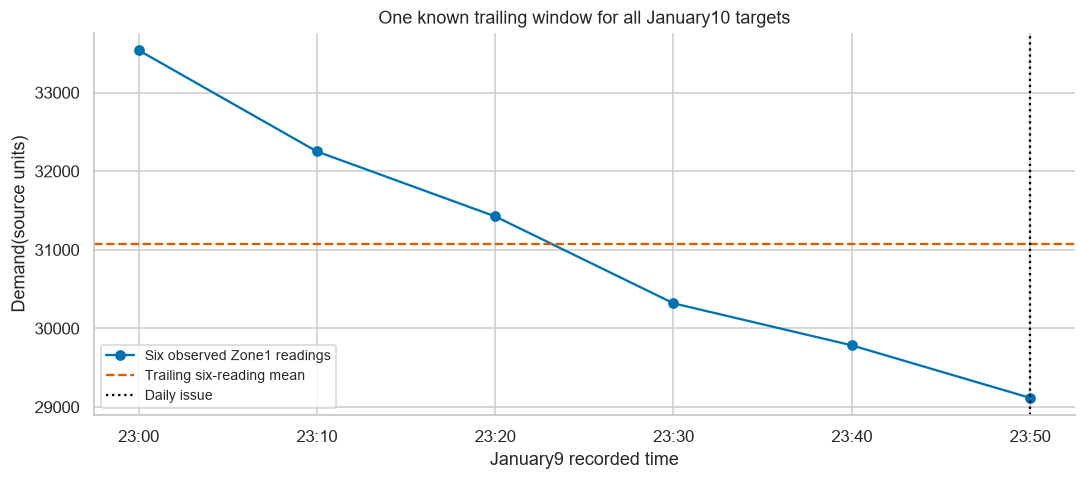

In [7]:
observed_dictionary=feature_dictionary.loc[feature_dictionary["source_reference"].ne("calendar")]
assert observed_dictionary["latest_origin_offset_max_minutes"].le(0).all()
availability_rows=[]
for row in observed_dictionary.itertuples(index=False):
    reference=panel["origin_time"] if row.source_reference=="origin" else panel["target_time"]
    earliest=reference-pd.to_timedelta(row.earliest_source_lag_steps*10,unit="min")
    latest=reference-pd.to_timedelta(row.latest_source_lag_steps*10,unit="min")
    assert latest.le(panel["origin_time"]).all() and earliest.le(latest).all()
    availability_rows.append({"feature":row.feature,"source_reference":row.source_reference,
        "minimum_latest_offset_minutes":((latest-panel["origin_time"])/pd.Timedelta(minutes=1)).min(),
        "maximum_latest_offset_minutes":((latest-panel["origin_time"])/pd.Timedelta(minutes=1)).max(),
        "all_rows_available":True})
availability=pd.DataFrame(availability_rows)
save_table(availability,"07_feature_availability_audit",index=False)

history=raw.set_index("datetime")
by_target=panel.set_index("target_time")
six=history.loc[example_origin-pd.Timedelta(minutes=50):example_origin,"zone1"]
assert len(six)==6
check_rows=[]
for target in example_targets:
    row=by_target.loc[target]
    expected={"zone1_at_origin":history.loc[example_origin,"zone1"],
        "zone1_target_lag_1d":history.loc[target-pd.Timedelta(days=1),"zone1"],
        "zone1_target_lag_7d":history.loc[target-pd.Timedelta(days=7),"zone1"],
        "zone1_origin_roll6_mean":six.mean(),
        "zone1_previous7_same_clock_mean":history.loc[[target-pd.Timedelta(days=k) for k in range(1,8)],"zone1"].mean()}
    for name,value in expected.items():
        assert np.isclose(row[name],value)
        check_rows.append({"target_time":target,"feature":name,"engineered":row[name],"independently_calculated":value})
check=pd.DataFrame(check_rows)
display(check.round({"engineered":4,"independently_calculated":4}))
save_table(check,"08_independent_feature_checks",index=False)
print("Every observed feature is available at its daily issue; independent early/middle/late checks passed.")

fig,ax=plt.subplots(figsize=(10,4.5))
ax.plot(six.index,six,marker="o",color=COLORS["zone1"],label="Six observed Zone1 readings")
ax.axhline(six.mean(),color="#D55E00",linestyle="--",label="Trailing six-reading mean")
ax.axvline(example_origin,color="black",linestyle=":",label="Daily issue")
ax.set(title="One known trailing window for all January10 targets",xlabel="January9 recorded time",
       ylabel="Demand(source units)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.legend(fontsize=9)
show_figure(fig,"04_example_trailing_window")

### Interpretation: One Shared History Window
The six-reading example window is January 9 **23:00–23:50**. Its mean is the same predictor for every January 10 target, including the first and last slots.

By contrast, previous-day and previous-week same-clock source timestamps change across those targets, while remaining no later than the daily issue. Both kinds of source rule passed the actual timestamp audit.

## 8. Perturb Future Measurements for an Entire Daily Batch
For three example days, change every weather and demand measurement strictly after the daily issue in a temporary copy. Rebuild features and verify that **all 144 target rows** in that day's batch retain identical predictors, while all 144 labels change.

This is a synthetic check, not modified modelling data. It specifically tests that later same-day observations cannot update a forecast that was already issued.

In [8]:
audit_days=[pd.Timestamp("2017-02-02"),pd.Timestamp("2017-09-01"),pd.Timestamp("2017-11-01")]
base_by_target=full_panel.set_index("target_time")
future_checks=[]
for day in audit_days:
    origin=day-ISSUE_OFFSET
    target_times=pd.date_range(day,periods=144,freq="10min")
    changed=raw.copy()
    future_rows=changed["datetime"].gt(origin)
    changed.loc[future_rows,WEATHER+ZONES]=changed.loc[future_rows,WEATHER+ZONES]*1.7+11
    altered,_=build_features(changed)
    original_batch=base_by_target.loc[target_times]
    altered_batch=altered.set_index("target_time").loc[target_times]
    unchanged=np.allclose(original_batch[feature_columns].to_numpy(dtype=float),altered_batch[feature_columns].to_numpy(dtype=float))
    changed_labels=(~np.isclose(original_batch["y_zone1"],altered_batch["y_zone1"])).sum()
    assert unchanged and changed_labels==144
    future_checks.append({"target_day":day,"issue":origin,"checked_targets":144,
                          "all_predictors_unchanged":unchanged,"changed_labels":int(changed_labels)})
future_audit=pd.DataFrame(future_checks)
display(future_audit)
save_table(future_audit,"09_future_batch_perturbation_checks",index=False)
print("All144 predictors rows remain unchanged in each of the three tested batches.")

All144 predictors rows remain unchanged in each of the three tested batches.


,target_day,issue,checked_targets,all_predictors_unchanged,changed_labels
0,2017-02-02,2017-02-01 23:50:00,144,True,144
1,2017-09-01,2017-08-31 23:50:00,144,True,144
2,2017-11-01,2017-10-31 23:50:00,144,True,144


### Interpretation: No Within-Day Forecast Updating
Changing the future left all 72 predictors unchanged across every target in each tested batch. All 144 target labels changed, so the test genuinely altered the future outcomes.

This verifies the implemented information boundary. Later model preprocessing must still be fitted using training data only; a valid feature table does not prevent a later model from leaking information through its fitting procedure.

## 9. Inspect Known Cyclic Fields and Training-Only Distributions
Target clock time is known for every next-day slot. Cyclic sine/cosine features preserve continuity across midnight and vary across the batch even though origin-relative history is frozen.

Inspect representative predictors using training rows only. Repeated origin values across144 target rows are expected; they do not represent144 independent weather observations. Any model-specific scaling or feature selection must be fitted later on training data only.

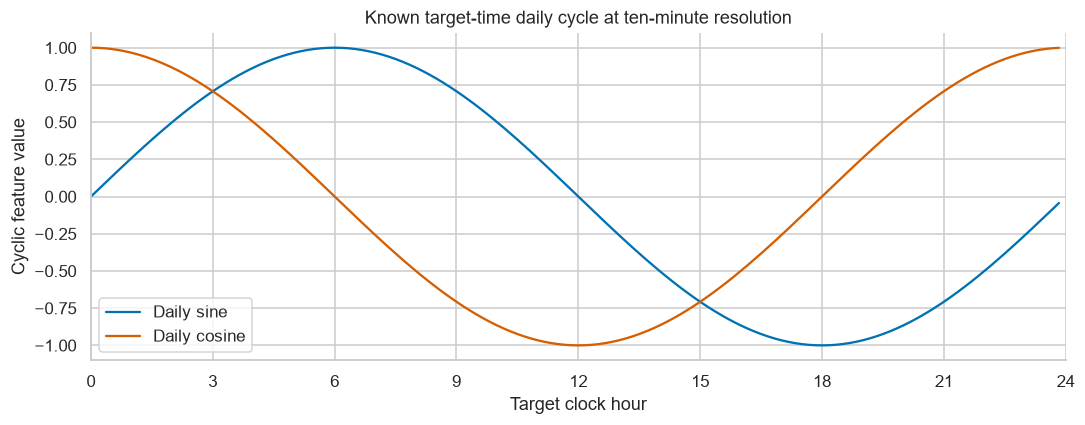

,count,mean,std,min,25%,50%,75%,max
zone1_at_origin,33840.0,34050.708,4575.700,24706.723,30331.139,31702.033,37991.761,45787.550
zone1_origin_roll144_mean,33840.0,33061.472,2554.173,26771.519,31266.179,32179.847,35269.502,38733.496
zone1_origin_roll144_std,33840.0,6807.226,513.370,5001.379,6523.208,6770.835,7142.559,9309.486
temperature_at_origin,33840.0,17.963,5.330,6.013,13.560,17.860,22.400,28.650
wind_speed_at_origin,33840.0,1.972,2.362,0.053,0.077,0.084,4.915,4.928
target_day_sin,33840.0,-0.000,0.707,-1.000,-0.707,0.000,0.707,1.000


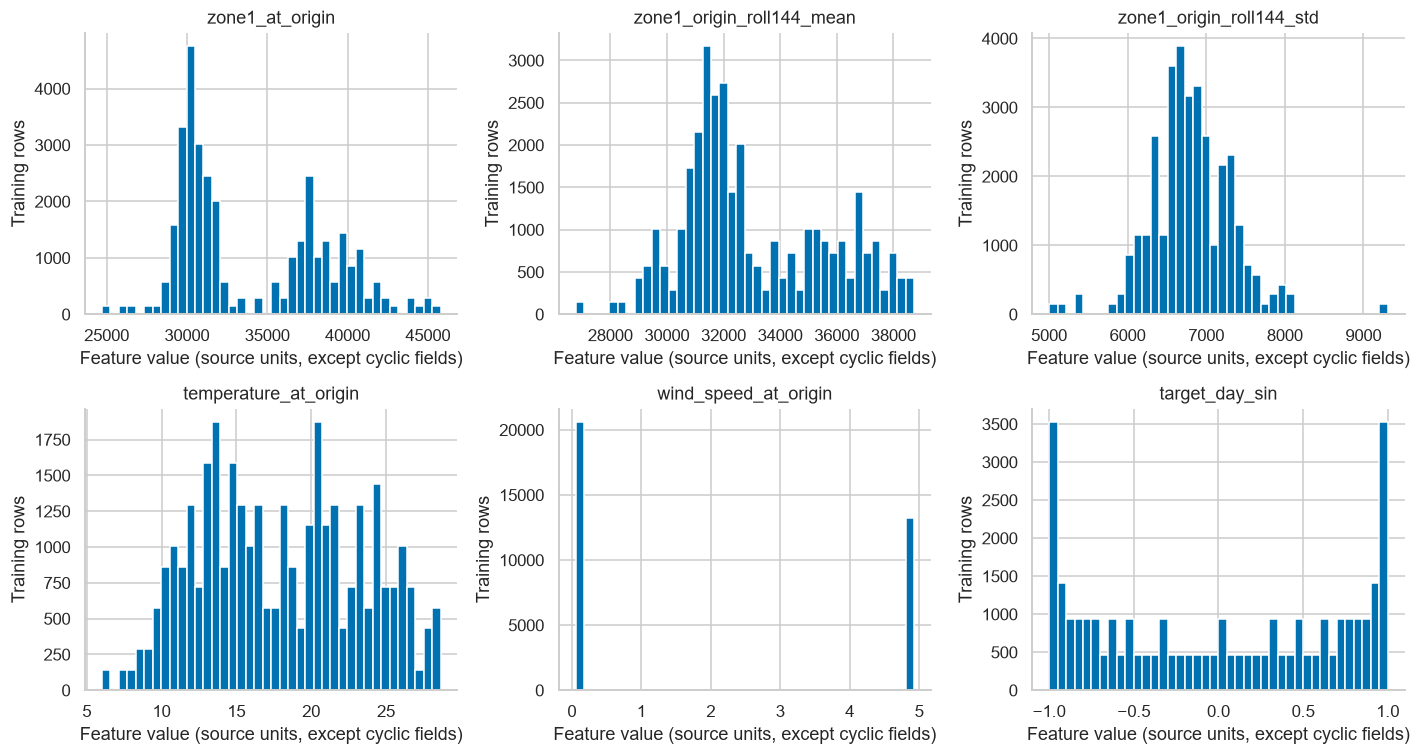

In [9]:
slots = np.arange(144)
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(slots/6,np.sin(2*np.pi*slots/144),label="Daily sine",color="#0072B2")
ax.plot(slots/6,np.cos(2*np.pi*slots/144),label="Daily cosine",color="#D55E00")
ax.set(title="Known target-time daily cycle at ten-minute resolution",xlabel="Target clock hour",
       ylabel="Cyclic feature value",xticks=range(0,25,3),xlim=(0,24))
ax.legend()
show_figure(fig,"05_daily_cyclic_encoding")

train = panel.loc[panel["split"].eq("train")].copy()
selected = ["zone1_at_origin","zone1_origin_roll144_mean","zone1_origin_roll144_std",
            "temperature_at_origin","wind_speed_at_origin","target_day_sin"]
display(train[selected].describe().T.round(3))
save_table(train[feature_columns].describe().T,"09_training_feature_statistics")
fig,axes=plt.subplots(2,3,figsize=(13,7))
for ax,name in zip(axes.flat,selected):
    ax.hist(train[name],bins=40,color="#0072B2",edgecolor="white")
    ax.set(title=name,xlabel="Feature value (source units, except cyclic fields)",ylabel="Training rows")
show_figure(fig,"06_training_feature_distributions")

### Interpretation: Known Target Time Versus Frozen History
The daily sine/cosine fields distinguish the144 target slots without revealing their outcomes. Origin-relative load/weather summaries remain frozen during that day.

The histograms count target rows, so each origin value is repeated across its144 forecasts. Different feature scales and shapes are expected. These are candidate predictors, not evidence that all should be included or that they improve validation forecasts.

## 10. Training-Only Feature–Target Correlations
Inspect the 12 largest absolute Pearson correlations with each zone's target demand using training rows only, retaining the sign.

Whole-day frozen origin values can have very different correlations from previous-day target-clock readings. Do not carry interpretations from the archived rolling design into this daily batch table. Correlation is descriptive, can miss nonlinear effects, and is not validation accuracy or automatic feature selection.

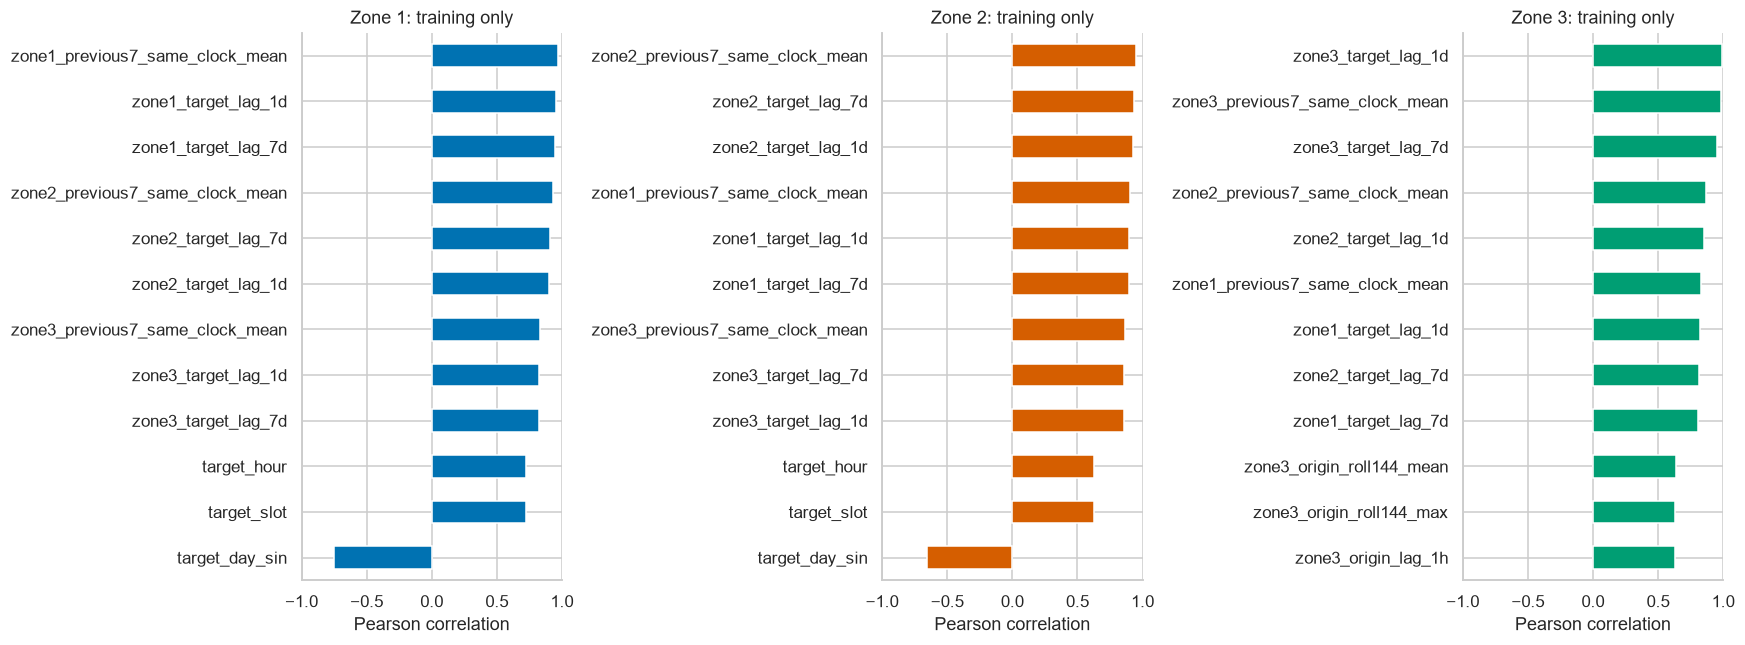

In [10]:
feature_target_corr = train[feature_columns+target_columns].corr().loc[feature_columns,[f"y_{z}" for z in ZONES]]
save_table(feature_target_corr,"10_training_feature_target_correlations")
fig,axes=plt.subplots(1,3,figsize=(16,6))
for ax,zone in zip(axes,ZONES):
    correlations = feature_target_corr[f"y_{zone}"]
    strongest = correlations.loc[correlations.abs().nlargest(12).index].sort_values()
    strongest.plot.barh(ax=ax,color=COLORS[zone])
    ax.set(title=f"{LABELS[zone]}: training only",xlabel="Pearson correlation",ylabel="",xlim=(-1,1))
show_figure(fig,"07_training_feature_target_correlations")

### Interpretation: Test the Whole Daily Pattern
Previous-day and previous-week target-clock features preserve a daily shape. Origin persistence carries just one late-night value into every next-day slot. Their different roles are now visible in the feature table and must be evaluated as distinct forecasting rules.

Training correlations motivate baseline comparisons, but do not determine the winning model. Notebook 05 will use identical whole-day validation targets and a declared MAE selection rule.

## 11. Save the Daily-Batch Feature Contract
Save one complete table with origin, target, lead, split, labels, and an explicit 72-column predictor list. The manifest declares one issue per day and variable leads; it deliberately does not use a scalar fixed-horizon contract.

Later notebooks should read these explicit lists instead of selecting all numeric columns, which could accidentally include labels or metadata. Source and feature-file hashes detect stale artifacts.

In [11]:
feature_path=PROCESSED_DIR/"tetuan_features_daily_batch.parquet"
manifest_path=PROCESSED_DIR/"tetuan_features_daily_batch_manifest.json"
manifest={
    "schema_version":2,"design_id":"daily_batch_2350",
    "forecast_design":"One daily issue at previous-day23:50 forecasting all144 next-calendar-day targets",
    "decision_status":"User-selected whole-next-day daily batch;23:50 issue is the documented implementation convention",
    "issue_clock":"23:50 previous day","step_minutes":10,"targets_per_issue":144,
    "lead_steps_min":1,"lead_steps_max":144,
    "origin_assumption":"Issue immediately after previous-day23:50 reading; no material reporting or fitting delay",
    "feature_columns":feature_columns,"target_columns":target_columns,
    "metadata_columns":["target_time","origin_time","lead_steps","split"],
    "feature_groups":{g:feature_dictionary.loc[feature_dictionary["group"].eq(g),"feature"].tolist()
                      for g in feature_dictionary["group"].unique()},
    "source_file":clean_path.name,"source_sha256":hashlib.sha256(clean_path.read_bytes()).hexdigest(),
    "feature_file":feature_path.name,"train_cutoff_exclusive":str(TRAIN_CUTOFF),
    "validation_cutoff_exclusive":str(VAL_CUTOFF),
    "split_rule":"Whole target-day split; latest fitting label <= first evaluation issue; no full-day gaps",
    "warmup_rows":1152,"retained_rows":len(panel),"retained_batches":356,
    "feature_records":json.loads(feature_dictionary.to_json(orient="records")),
    "no_target_day_observed_weather":True,"full_file_explored_descriptively":True}
panel.to_parquet(feature_path,index=False,engine="pyarrow")
manifest["feature_sha256"]=hashlib.sha256(feature_path.read_bytes()).hexdigest()
manifest_path.write_text(json.dumps(manifest,indent=2,ensure_ascii=False,allow_nan=False),encoding="utf-8")
pd.testing.assert_frame_equal(panel,pd.read_parquet(feature_path))
saved_manifest=json.loads(manifest_path.read_text(encoding="utf-8"))
assert saved_manifest["feature_columns"]==feature_columns
assert "horizon_steps" not in saved_manifest
pd.testing.assert_frame_equal(pd.read_parquet(clean_path),raw)
figure_names=["01_source_origin_target_timeline","02_initial_history_requirements","03_split_coverage",
              "04_example_trailing_window","05_daily_cyclic_encoding","06_training_feature_distributions",
              "07_training_feature_target_correlations"]
for name in figure_names:
    for extension in ["png","svg"]:assert (FEATURE_FIGURES/f"{name}.{extension}").stat().st_size>0
print(f"Saved {len(panel):,} rows,356 daily batches,and{len(feature_columns)} predictors.")
print("Feature table:",feature_path)
print("Manifest:",manifest_path)
print("Save/reload verified. Cleaned input unchanged. Earlier rolling outputs are superseded.")

Saved 51,264 rows,356 daily batches,and72 predictors.
Feature table: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\processed\tetuan_features_daily_batch.parquet
Manifest: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\processed\tetuan_features_daily_batch_manifest.json
Save/reload verified. Cleaned input unchanged. Earlier rolling outputs are superseded.


## 12. Conclusions and Next Step
The current contract issues one batch at previous-day23:50 for all 144 next-day targets. It uses72 candidate predictors, with source-time rules and a variable lead of 10 minutes–24 hours.

There are 51,264 retained target rows: 33,840 training,8,784 validation,and8,640 later test rows. Complete daily batches, frozen origin features, individual source-time checks,and entire-batch future-perturbation checks are verified.

### Explain during the defence
- One daily origin is shared by all 144 targets; lead times vary across the day.
- Origin persistence and previous-day demand are distinct in this design.
- Origin-relative history is frozen,but past-day same-clock values vary by target while remaining known at issue.
- Target-relative source offsets must be checked against the shared origin,not treated as fixed origin lags.
- September 1 and November 1 are included because their issues already have the required fitting labels,under the stated negligible-delay assumption.
- No target-day observations are used to update an already-issued batch.

### Next: Notebook 05 — Daily-Batch Baselines
Compare origin persistence,previous day,previous week,seven-day same-clock mean,and a training-only weekly profile on the same61 validation days. MAE remains the declared primary selection metric; later final test scoring remains reserved.

The archived rolling scores used different validation targets and must not be mixed with these results.